# Описание данных

Набор данных содержит оценки степени согласия респондентов с высказываниями,
отражающими цель потребления леденцов. Всего каждый респондент выставлял оценки по 11 высказываниям:


*   V1: Я потребляю леденцы, чтобы освежить дыхание
*   V2: Я потребляю леденцы, чтобы чувствовать себя увереннее
*   V3: Я потребляю леденцы, чтобы освежить полость рта
*   V4: Я потребляю леденцы, чтобы избавиться от неприятного вкуса во рту
*   V5: Я потребляю леденцы как заменитель других кондитерских изделий
*   V6: Я потребляю леденцы, когда мне хочется чего-нибудь сладкого
*   V7: Леденцы помогают мне сконцентрироваться
*   V8: Я потребляю леденцы, чтобы отвлечься на несколько минут и подумать
*   V9: Я потребляю леденцы для того, чтобы облегчить боль в горле
*   V10: Я потребляю леденцы для того, чтобы избавиться от заложенности носа
*   V11: Я потребляю леденцы для улучшения самочувствия

In [20]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
matplotlib.style.use('ggplot')
%matplotlib inline

from sklearn.cluster import KMeans

In [21]:

from google.colab import files

#print("Пожалуйста, загрузите файл 'Леденцы.dat'")
#uploaded = files.upload()
df = pd.read_csv('Леденцы.dat', sep=';')

df.head(10)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3
5,5,4,5,5,3,3,3,3,3,3,3
6,5,5,4,5,3,3,3,3,3,3,3
7,5,4,5,5,3,3,3,3,3,3,3
8,5,5,5,5,3,3,3,3,3,3,3
9,5,4,5,4,3,3,3,3,3,3,3


In [22]:
df.shape

(338, 11)

Посмотрим в какой шкале респонденты отвечали на вопрос.

In [23]:
uniq=df.apply(lambda s: np.sort(s.unique()))
print(uniq)

   V1  V2  V3  V4  V5  V6  V7  V8  V9  V10  V11
0   2   2   2   2   2   2   2   2   2    2    2
1   3   3   3   3   3   3   3   3   3    3    3
2   4   4   4   4   4   4   4   4   4    4    4
3   5   5   5   5   5   5   5   5   5    5    5


Отсюда видно, что по каждому вопросу респонденты ставили от 2 до 5 "согласны ли они с утверждением". Можно предположить, что использовалась стандартная шкала оценивания - от 1 до 5.

# Кластеризация


Для определения числа кластеров построим график "каменистой осыпи"

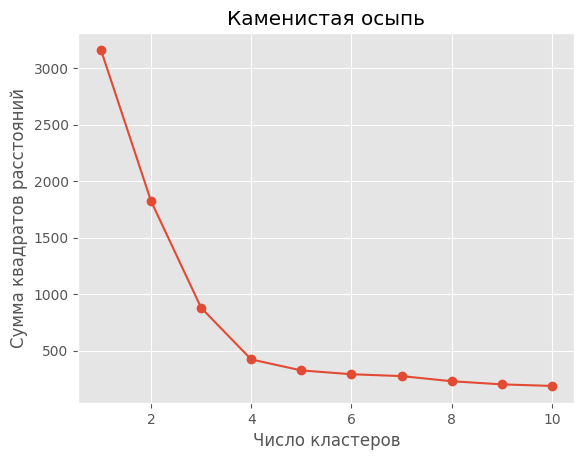

In [24]:
K = range(1, 11)

# Вычисляем значения критерия качества для разного числа кластеров
models = [KMeans(n_clusters=k, random_state=42).fit(df) for k in K]
dist = [model.inertia_ for model in models]

# Строим график каменистая осыпь
plt.plot(K, dist, marker='o')
plt.xlabel('Число кластеров')
plt.ylabel('Сумма квадратов расстояний')
plt.title('Каменистая осыпь')
plt.show()

Явный излом приходится на 4 кластера. Проверим верно ли данное число с помощью вычисления коэффициента силуэта:

In [25]:
from sklearn.metrics import silhouette_score

silhouette_scores = []
K_range = range(2, 11) # Силуэт не считается для 1 кластера

for k in K_range:
    # Обучаем модель для текущего k
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X)

    # Считаем силуэт
    score = silhouette_score(X, labels)
    silhouette_scores.append(score)
    print(f"Число кластеров: {k}, Silhouette Score: {score:.3f}")

# Строим график
#plt.figure(figsize=(8, 5))
#plt.plot(K_range, silhouette_scores, marker='o', linestyle='-', color='purple')
#plt.title('Коэффициент силуэта')
#plt.xlabel('Число кластеров k')
#plt.ylabel('Silhouette Score ')
#plt.axvline(x=4, color='red', linestyle='--', label='Выбранное k=4')
#plt.xticks(K_range)
#plt.legend()
#plt.grid(True)
#plt.show()

Число кластеров: 2, Silhouette Score: 0.447
Число кластеров: 3, Silhouette Score: 0.597
Число кластеров: 4, Silhouette Score: 0.708
Число кластеров: 5, Silhouette Score: 0.689
Число кластеров: 6, Silhouette Score: 0.716
Число кластеров: 7, Silhouette Score: 0.644
Число кластеров: 8, Silhouette Score: 0.729
Число кластеров: 9, Silhouette Score: 0.660
Число кластеров: 10, Silhouette Score: 0.669


С выбранным числом кластеров обучим модель и добавим столбик с указанием кластера в датасет.

In [26]:
model = KMeans(n_clusters=4, random_state=42, max_iter=300, n_init=10, verbose=0)
model.fit(df)
df['cluster'] = model.labels_
df.groupby('cluster').mean()


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
cluster,,,,,,,,,,,
0,2.824074,2.833333,2.768519,2.620370,2.611111,2.583333,2.750000,2.916667,4.953704,4.814815,4.861111
1,3.000000,3.000000,3.000000,3.000000,4.852459,4.852459,3.000000,2.918033,2.754098,2.754098,2.754098
2,4.845455,4.800000,4.836364,4.681818,3.036364,3.036364,3.000000,2.990909,3.072727,3.045455,3.045455
3,3.000000,2.966102,2.966102,2.915254,2.915254,2.949153,4.915254,4.915254,3.000000,3.000000,3.000000


In [27]:
model.cluster_centers_

array([[2.82407407, 2.83333333, 2.76851852, 2.62037037, 2.61111111,
        2.58333333, 2.75      , 2.91666667, 4.9537037 , 4.81481481,
        4.86111111],
       [3.        , 3.        , 3.        , 3.        , 4.85245902,
        4.85245902, 3.        , 2.91803279, 2.75409836, 2.75409836,
        2.75409836],
       [4.84545455, 4.8       , 4.83636364, 4.68181818, 3.03636364,
        3.03636364, 3.        , 2.99090909, 3.07272727, 3.04545455,
        3.04545455],
       [3.        , 2.96610169, 2.96610169, 2.91525424, 2.91525424,
        2.94915254, 4.91525424, 4.91525424, 3.        , 3.        ,
        3.        ]])

Проверим количество наблюдений в каждом кластере:

In [28]:
print(df['cluster'].value_counts())

cluster
2    110
0    108
1     61
3     59
Name: count, dtype: int64


Обратив внимание на распределение значений по каждому кластеру, можно сделать следующие выводы.

0й кластер содержит 108 наблюдений. Наиболее высокие оценки здесь респонденты дали следующим высказываниям: **V9** (облегчить боль в горле, ~4.95), **V10** (заложенность носа, ~4.81) и **V11** (улучшение самочувствия, ~4.86). Остальные показатели находятся на среднем уровне. Таким образом, можно сделать вывод, что этот сегмент потребителей, которые воспринимают леденцы в первую очередь как средство для лечения симптомов простуды.

1й кластер содержит 110 наблюдений. Здесь наиболее высоко были оценены высказывания:  **V1** (освежить дыхание, ~4.85), **V2** (уверенность, ~4.80), **V3** (освежить полость рта, ~4.84) и **V4** (избавиться от неприятного вкуса, ~4.68). То есть для потребителей этого кластера леденцы — это средство личной гигиены и поддержания уверенности в общении.

2й кластер содержит 59 наблюдений. Наиболее высокие оценки здесь респонденты дали следующим высказываниям: **V7** (помогают сконцентрироваться, ~4.92) и **V8** (отвлечься и подумать, ~4.92). Остальные значения — фоновые (около 3.0). Это сегмент потребителей, для которых леденцы - это способ снять стресс, сделать паузу в работе или сфокусироваться.

3й  кластер содержит 61 наблюдение. Здесь наиболее высоко были оценены высказывания: **V5** (заменитель кондитерских изделий, ~4.85) и **V6** (хочется сладкого, ~4.85). Можно сказать, что для этого сегмента леденцы воспринимаются как десерт и вкусное лакомство, а не средство гигиены или лекарство.

# Дополнительно


In [31]:
from sklearn.metrics import pairwise_distances
X = df.drop(columns=['cluster'])
# Считаем расстояния от каждой точки до ВСЕХ центроидов
distances = pairwise_distances(X, model.cluster_centers_)

# Извлекаем расстояние от каждой точки до ЕЁ СОБСТВЕННОГО центроида
# (model.labels_ содержит индексы 0, 1, 2, 3, которые указывают на нужный столбец в distances)
own_distances = distances[np.arange(len(X)), model.labels_]

# Записываем в датафрейм для удобства
df['dist_to_center'] = own_distances

# Считаем среднее расстояние для каждого кластера
print("Среднее евклидово расстояние от точек до центроида (оценка плотности):")
print(df.groupby('cluster')['dist_to_center'].mean().round(2))

Среднее евклидово расстояние от точек до центроида (оценка плотности):
cluster
0    1.39
1    0.83
2    0.85
3    0.37
Name: dist_to_center, dtype: float64


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


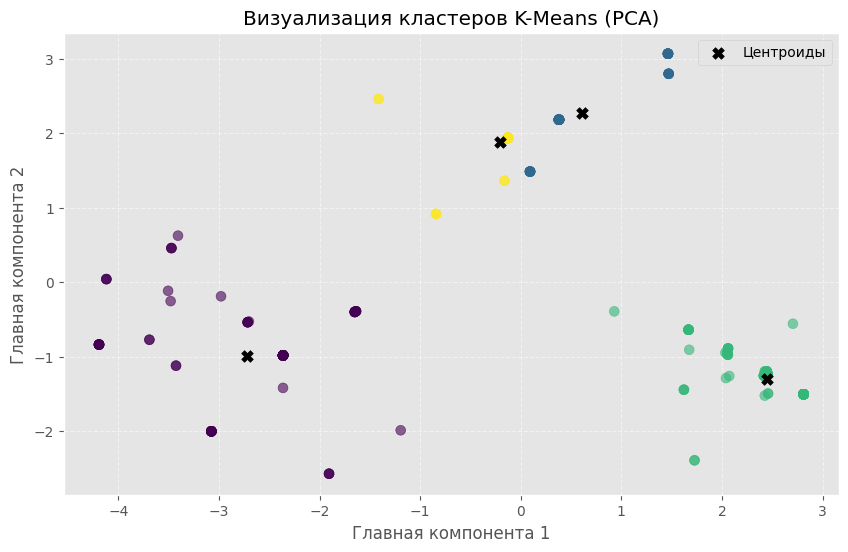

In [34]:
from sklearn.decomposition import PCA

# 1. Сжимаем данные до 2-х измерений для графика
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# 2. Сжимаем центроиды по тем же правилам
centers_pca = pca.transform(model.cluster_centers_)

# 3. Строим график
plt.figure(figsize=(10, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=model.labels_, cmap='viridis', alpha=0.6, s=50)

# 4. Добавляем центроиды
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], marker='X', s=70, c='black', label='Центроиды')

plt.title('Визуализация кластеров K-Means (PCA)')
plt.xlabel('Главная компонента 1')
plt.ylabel('Главная компонента 2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

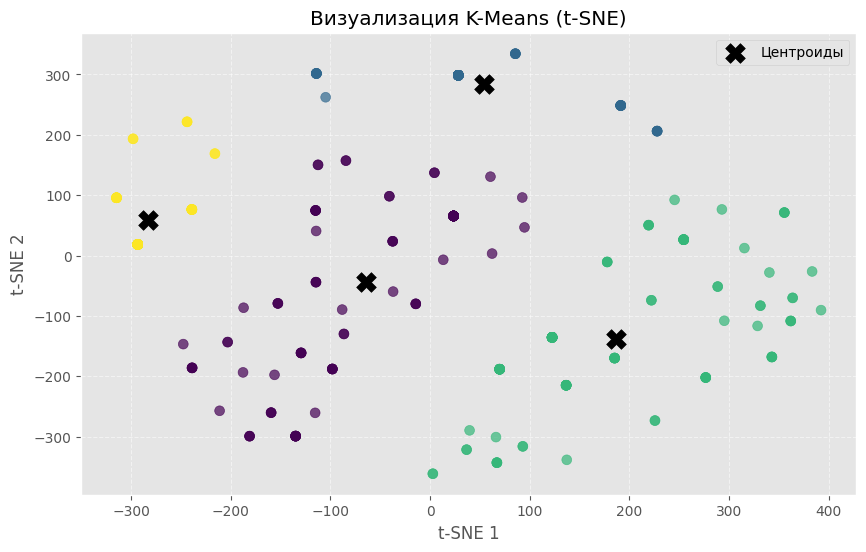

In [36]:
from sklearn.manifold import TSNE

# 1. Инициализируем t-SNE (perplexity обычно ставят от 5 до 50)
tsne = TSNE(n_components=2, perplexity=30, random_state=42, init='pca', learning_rate='auto')
X_tsne = tsne.fit_transform(X)

# 2. Строим график
plt.figure(figsize=(10, 6))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=model.labels_, cmap='viridis', alpha=0.7, s=50)

# Добавим центроиды (для t-SNE мы просто берем среднее координат точек каждого кластера на графике)
centers_tsne = np.array([X_tsne[model.labels_ == i].mean(axis=0) for i in range(4)])
plt.scatter(centers_tsne[:, 0], centers_tsne[:, 1], marker='X', s=200, c='black', label='Центроиды')

plt.title('Визуализация K-Means (t-SNE)')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Выводы о результате работы

В ходе лабораторной работы был проведен кластерный анализ методом k-means по данным опроса потребителей леденцов (338 респондентов, 11 переменных).

1. Для определения оптимального числа кластеров был использован С график «каменистой осыпи» и коэффициент силуэта. В обоих ислучаях - излом или наиближайшее значение к 1 (~0.72) - достигается при количестве кластеров 4.
2.  Была проведена оченка плотности с помощью расчета среднего евклидова расстояния от точек до центроидов.
3.  Для визуалищации распределение данных в полученных кластеров использовались два метода - . На мой взгляд, лучше отражает корректность разбиения именно на 4 кластера.
4.  Данные, полученные для кластеров, можно по интерпретации полученных значений разделить на 4 четко легко обьяснимых сегмента: «Лечебный», «Свежесть дыхания», «Психологический» и «Сладкоежки».